#Partie I : Extraction de Caractéristiques

In [ ]:
import cv2
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from skimage import exposure
from skimage import feature
from imutils import paths
import imutils
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

#	Préparation des données de Train  & Extraction des caractéristiques HOG

[INFO] Extraction des caractéristiques : valeurs brutes, histogramme de couleurs, HOG, LBP
caltech_dataset/train_set\car\01.png


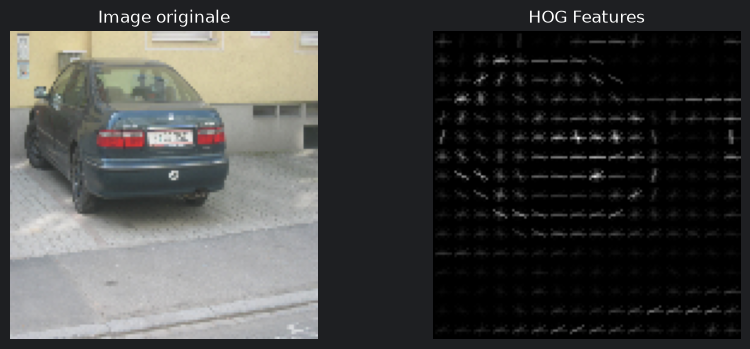

caltech_dataset/train_set\car\02.png


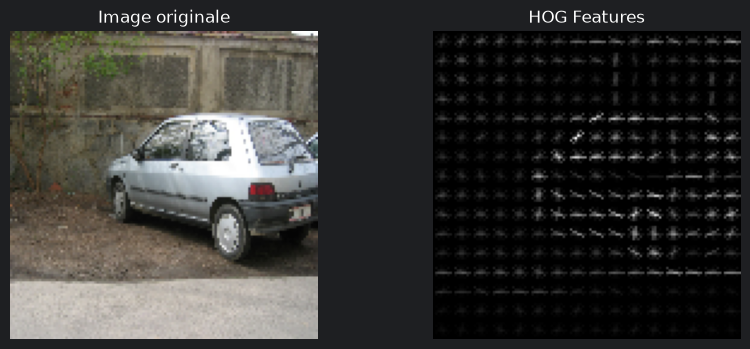

caltech_dataset/train_set\car\03.png


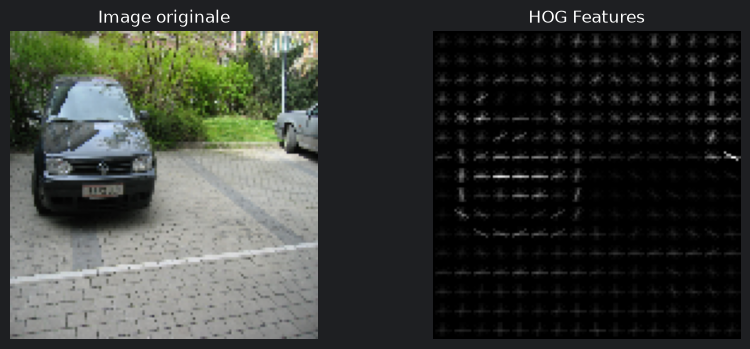

caltech_dataset/train_set\car\04.png


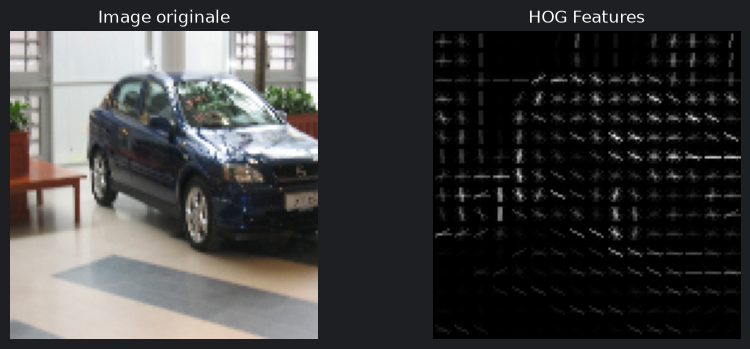

caltech_dataset/train_set\car\05.png


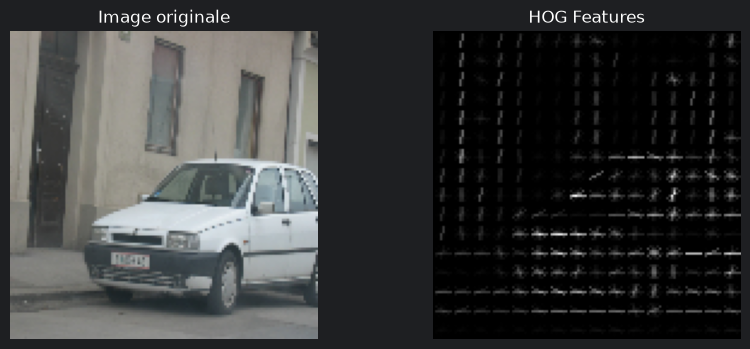

caltech_dataset/train_set\car\06.png


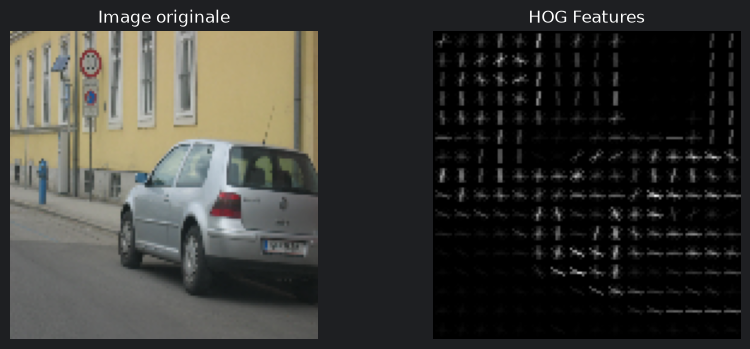

caltech_dataset/train_set\car\07.png


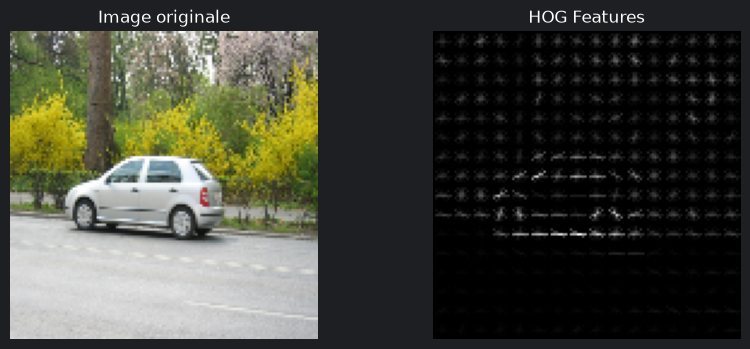

caltech_dataset/train_set\car\08.png


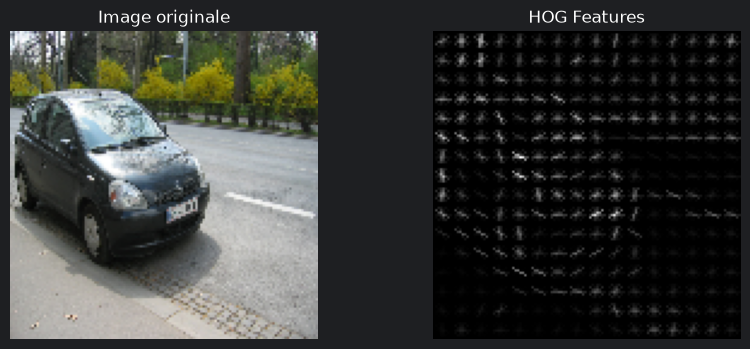

caltech_dataset/train_set\car\09.png


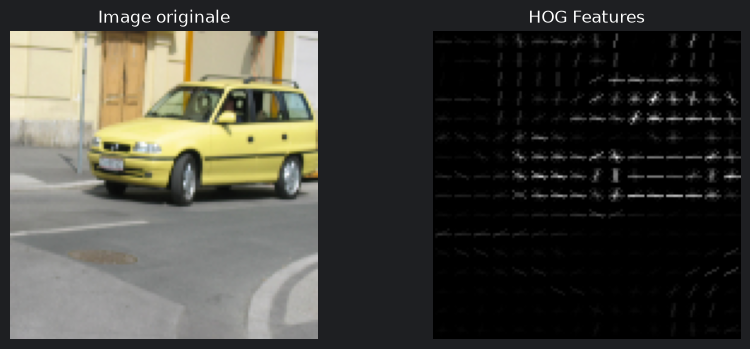

caltech_dataset/train_set\car\10.png


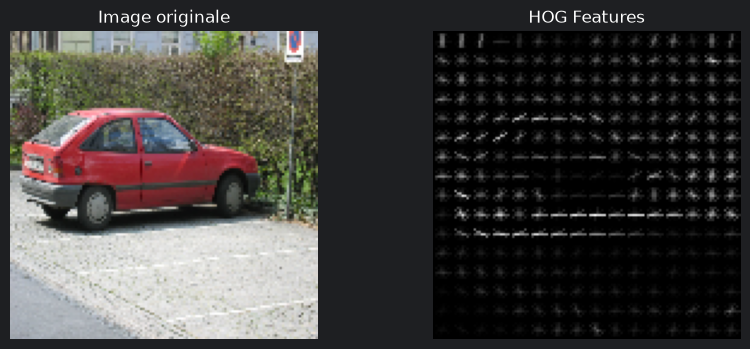

caltech_dataset/train_set\car\11.png


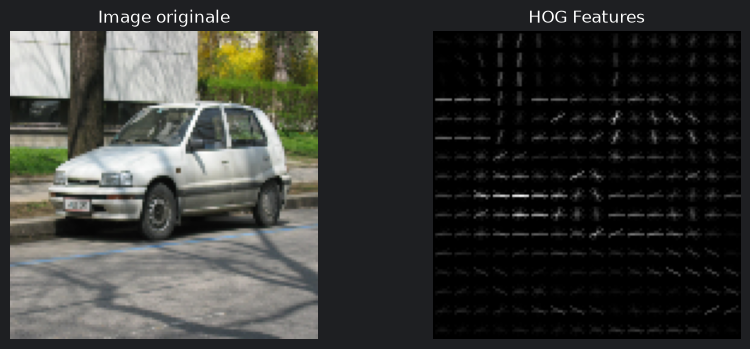

caltech_dataset/train_set\car\12.png


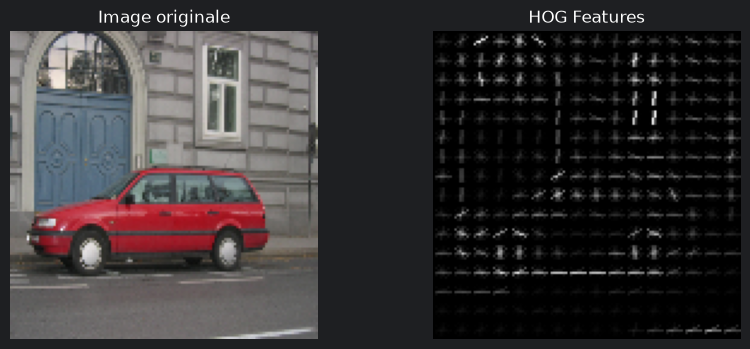

caltech_dataset/train_set\car\13.png


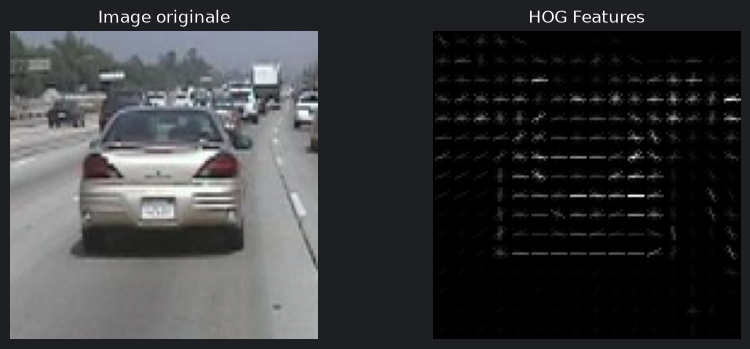

caltech_dataset/train_set\car\14.png


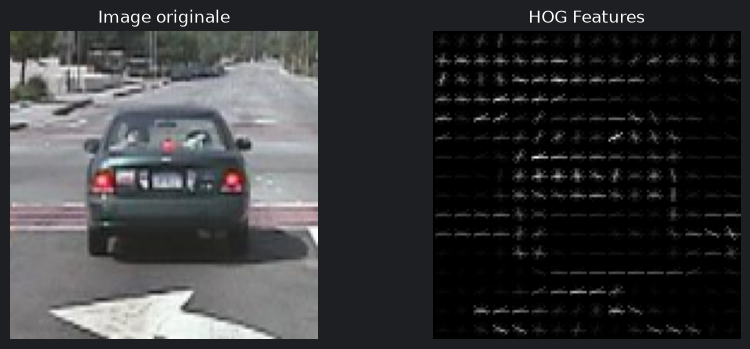

caltech_dataset/train_set\car\15.png


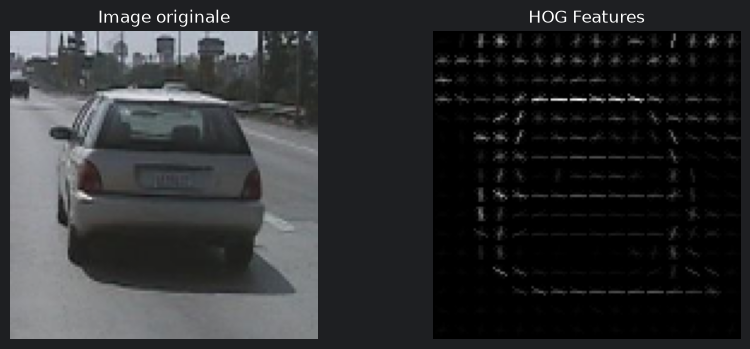

caltech_dataset/train_set\car\16.png


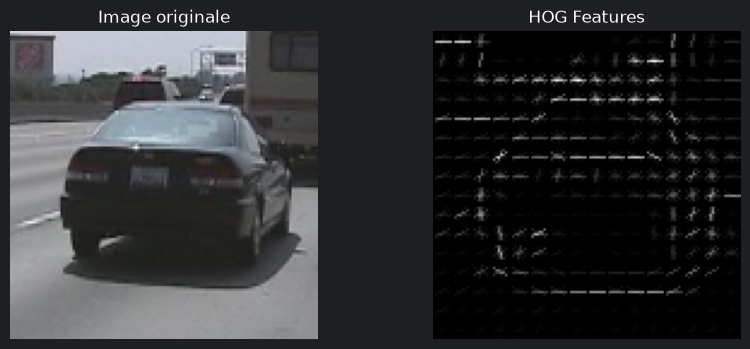

caltech_dataset/train_set\car\17.png


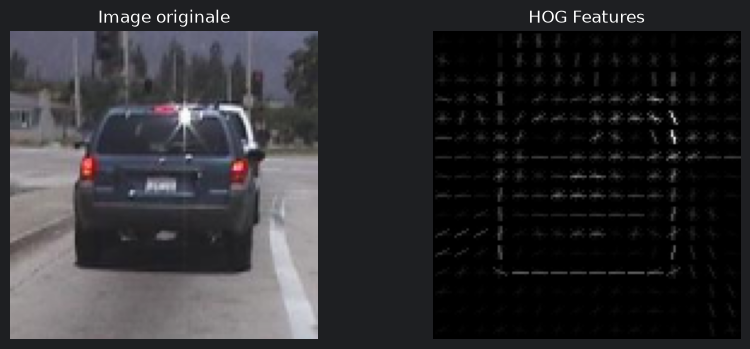

caltech_dataset/train_set\car\18.png


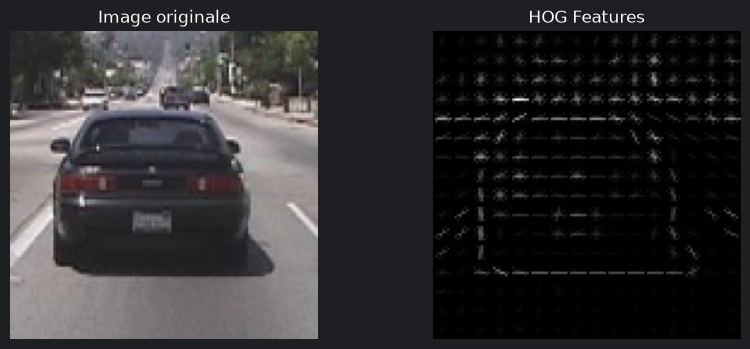

caltech_dataset/train_set\car\19.png


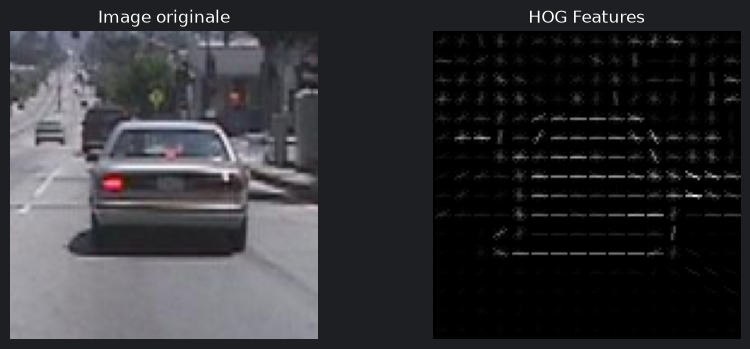

caltech_dataset/train_set\car\20.png


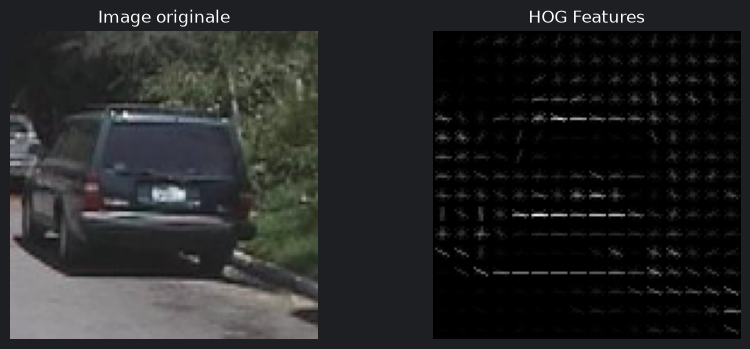

caltech_dataset/train_set\motorbike\01.png


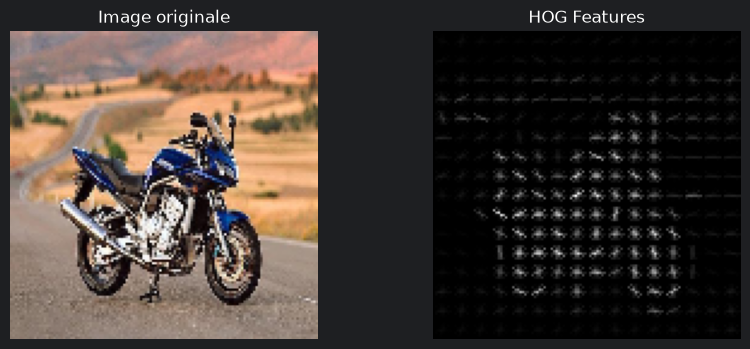

caltech_dataset/train_set\motorbike\02.png


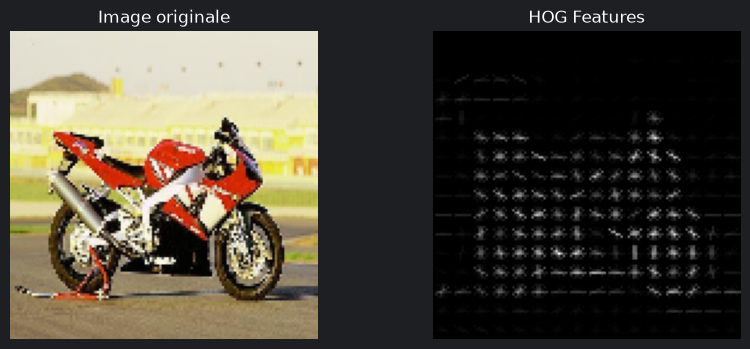

caltech_dataset/train_set\motorbike\03.png


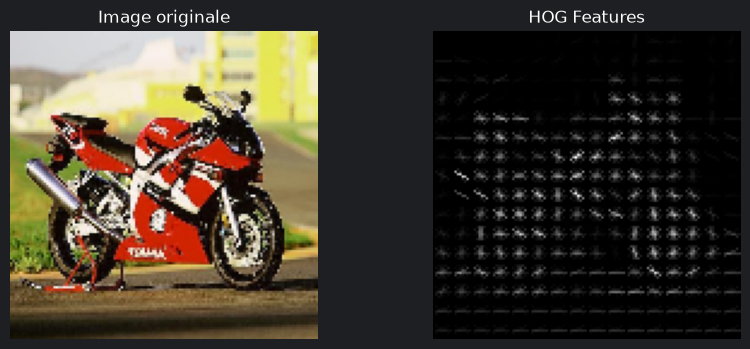

caltech_dataset/train_set\motorbike\04.png


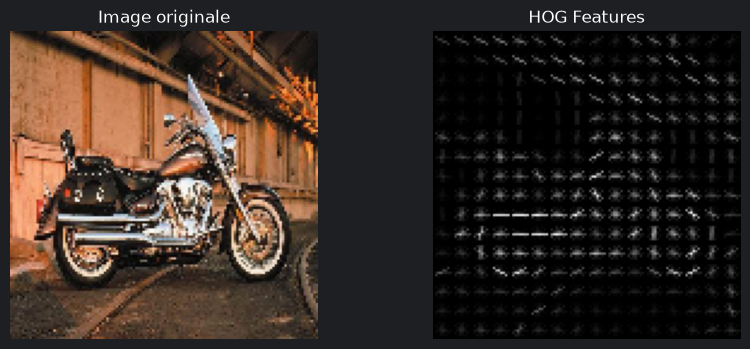

caltech_dataset/train_set\motorbike\05.png


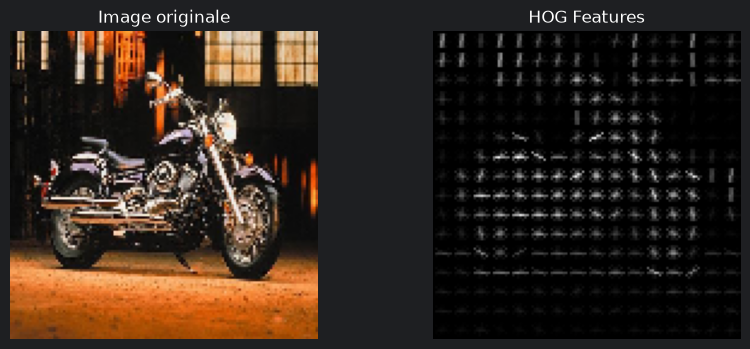

caltech_dataset/train_set\motorbike\06.png


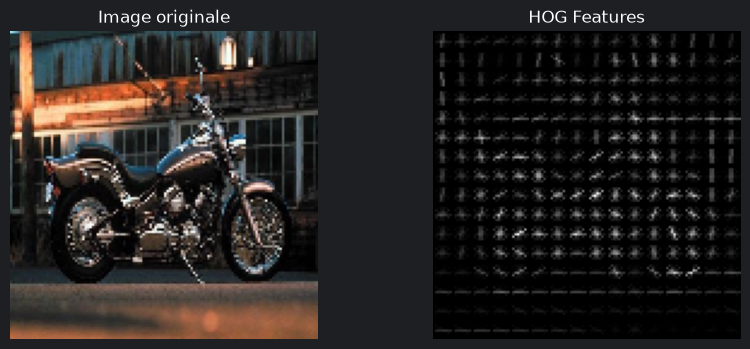

caltech_dataset/train_set\motorbike\07.png


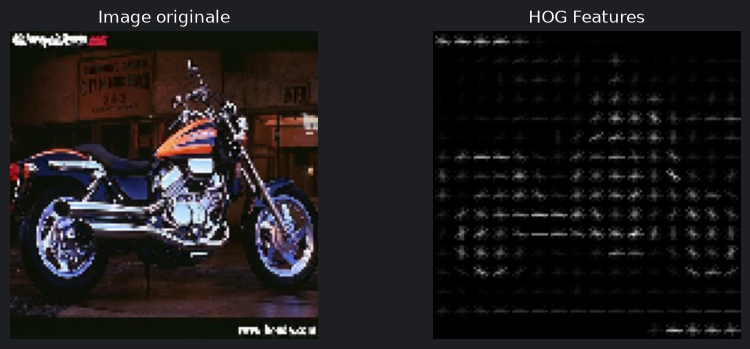

caltech_dataset/train_set\motorbike\08.png


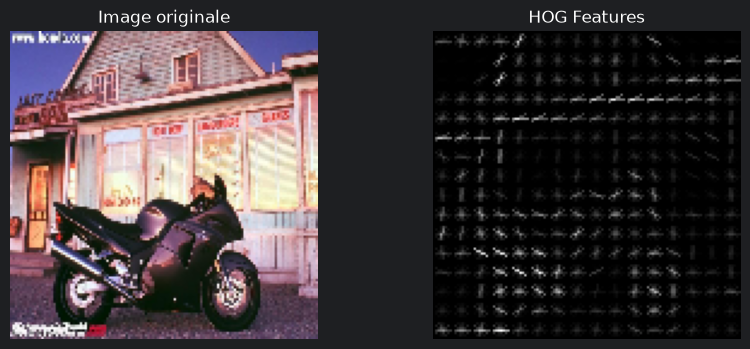

caltech_dataset/train_set\motorbike\09.png


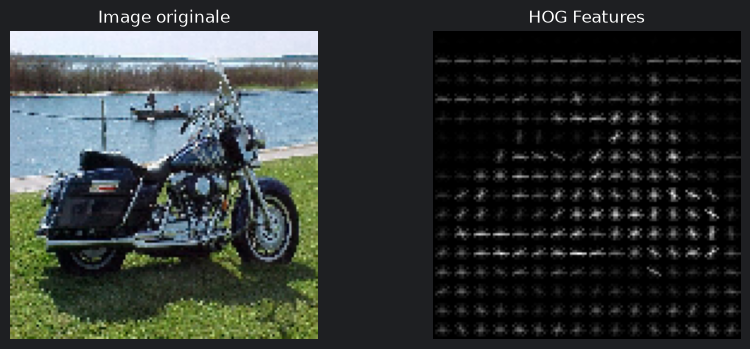

caltech_dataset/train_set\motorbike\10.png


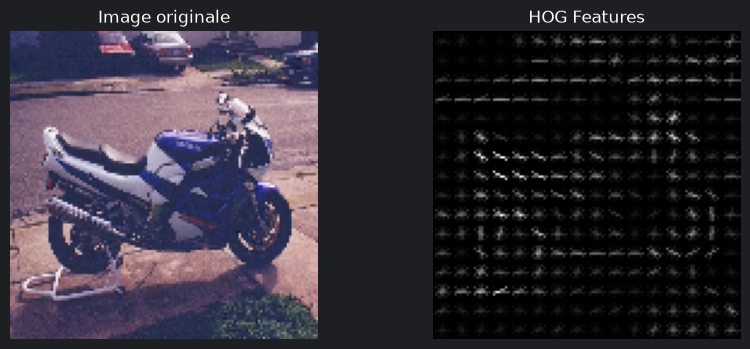

caltech_dataset/train_set\motorbike\11.png


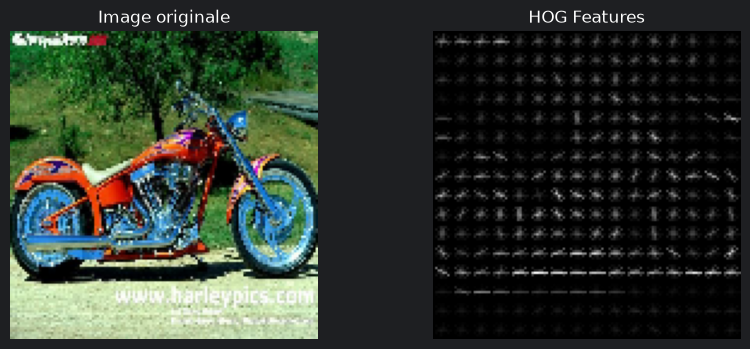

caltech_dataset/train_set\motorbike\12.png


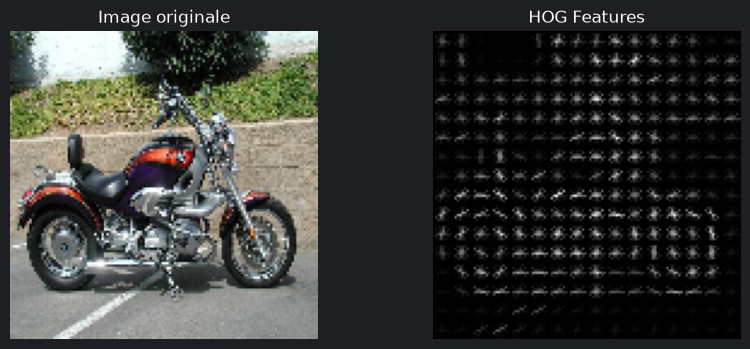

caltech_dataset/train_set\motorbike\13.png


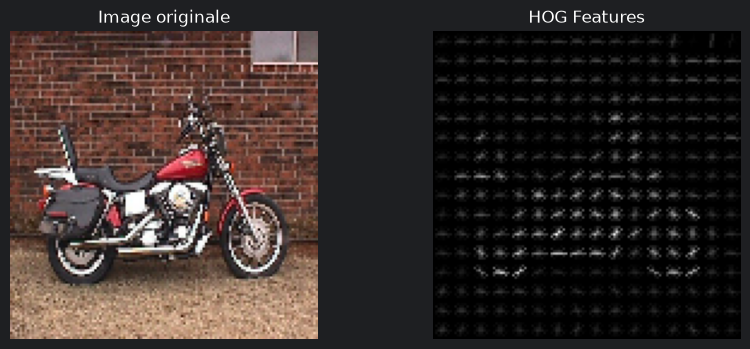

caltech_dataset/train_set\motorbike\14.png


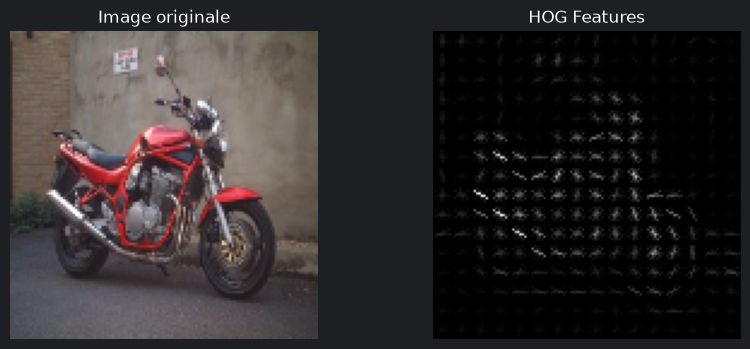

caltech_dataset/train_set\motorbike\15.png


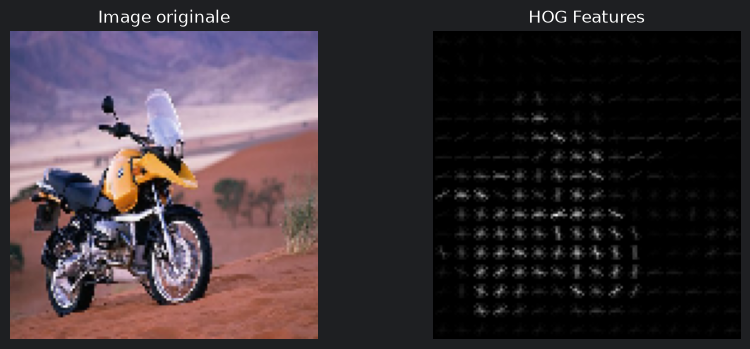

caltech_dataset/train_set\motorbike\16.png


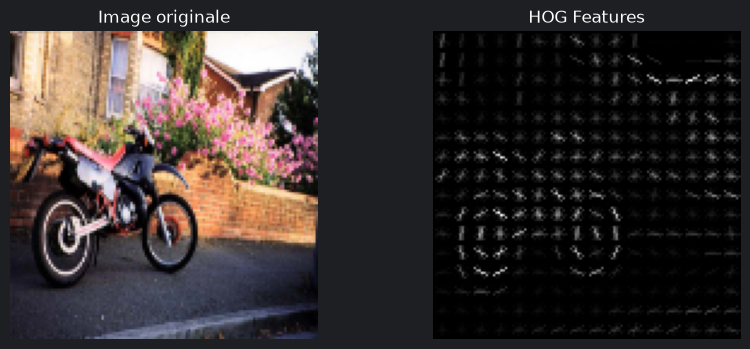

caltech_dataset/train_set\motorbike\17.png


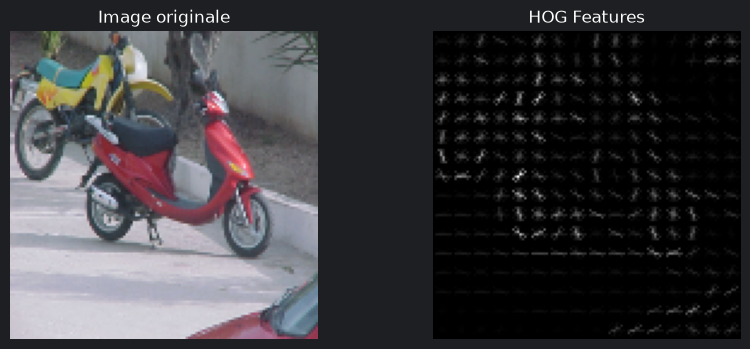

caltech_dataset/train_set\motorbike\18.png


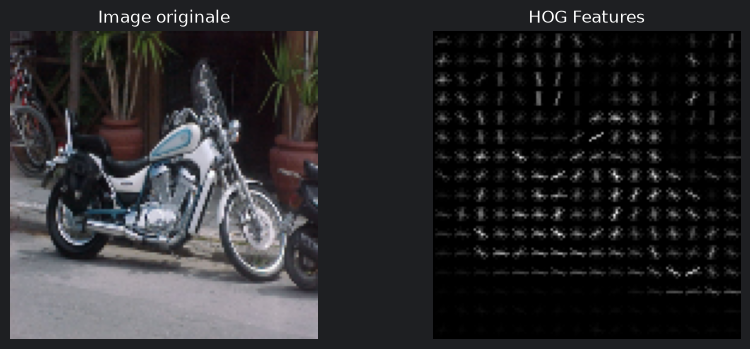

caltech_dataset/train_set\motorbike\19.png


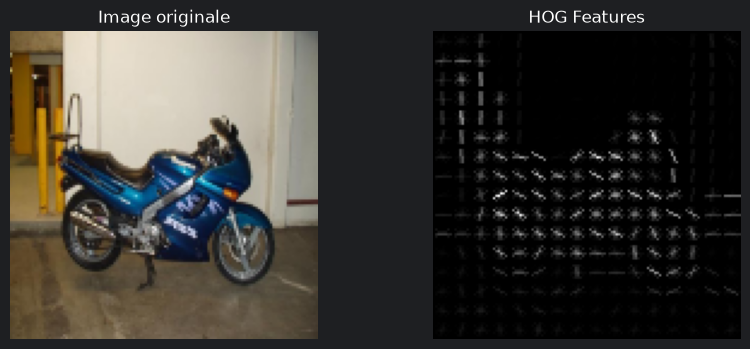

caltech_dataset/train_set\motorbike\20.png


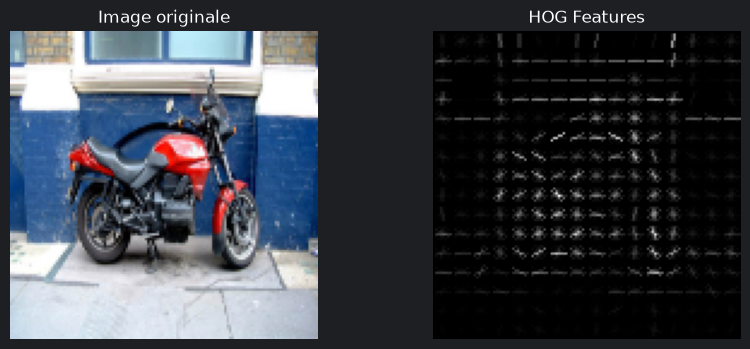

caltech_dataset/train_set\person\01.png


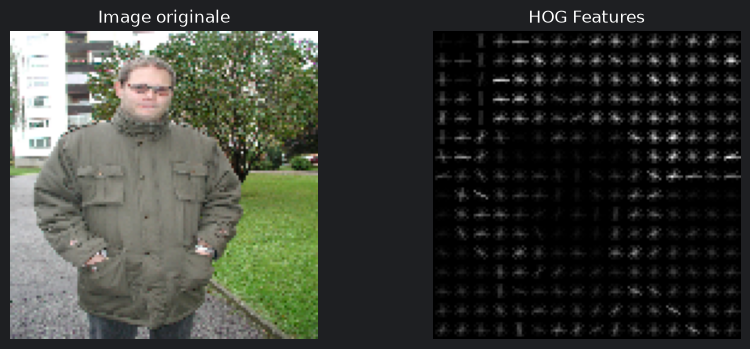

caltech_dataset/train_set\person\02.png


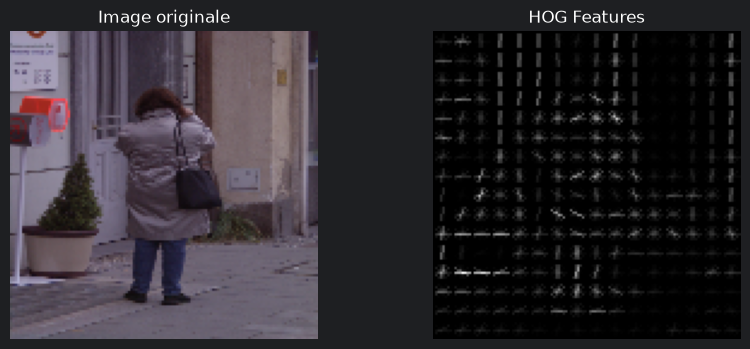

caltech_dataset/train_set\person\03.png


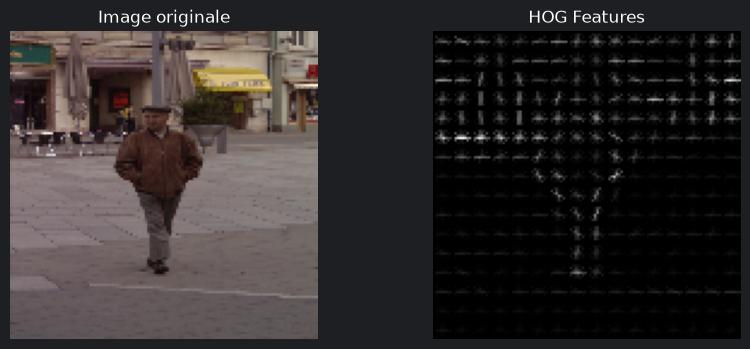

caltech_dataset/train_set\person\04.png


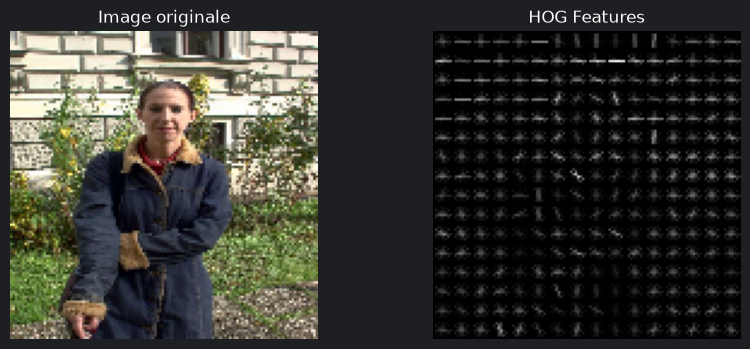

caltech_dataset/train_set\person\05.png


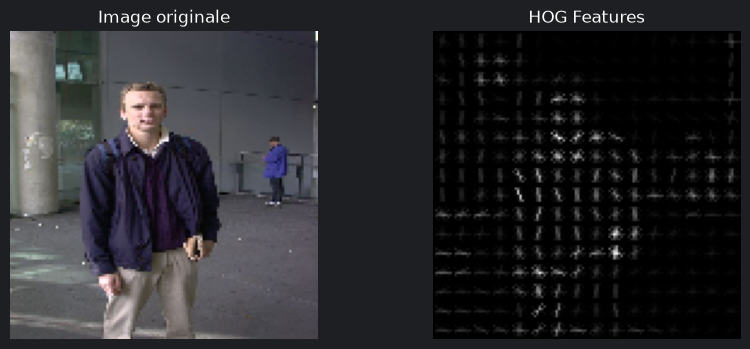

caltech_dataset/train_set\person\06.png


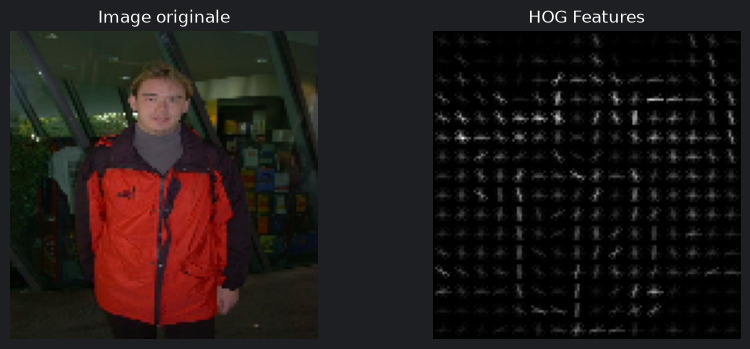

caltech_dataset/train_set\person\07.png


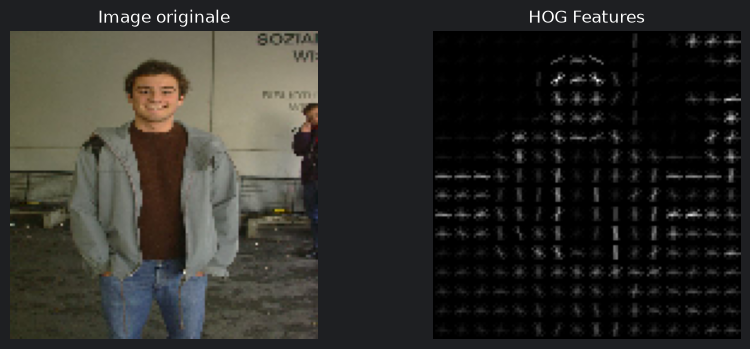

caltech_dataset/train_set\person\08.png


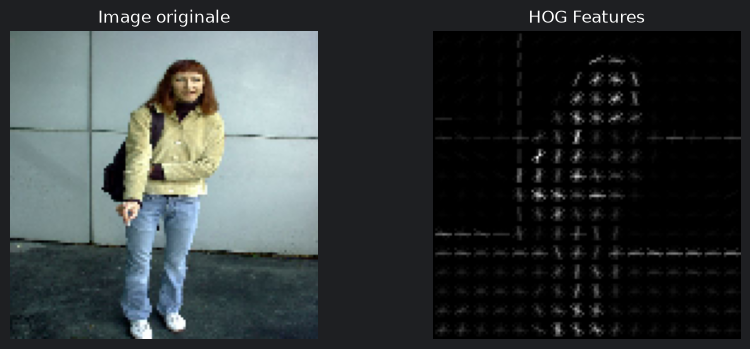

caltech_dataset/train_set\person\09.png


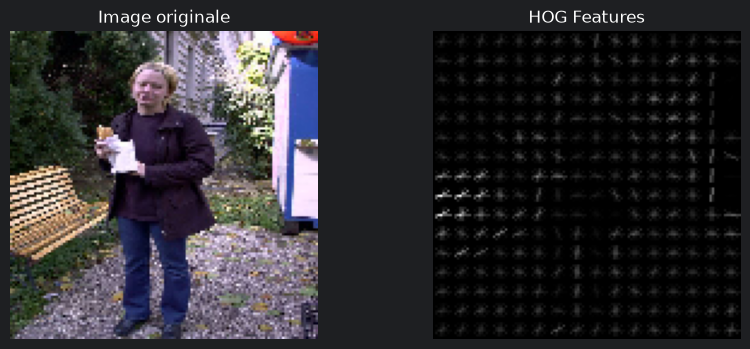

caltech_dataset/train_set\person\10.png


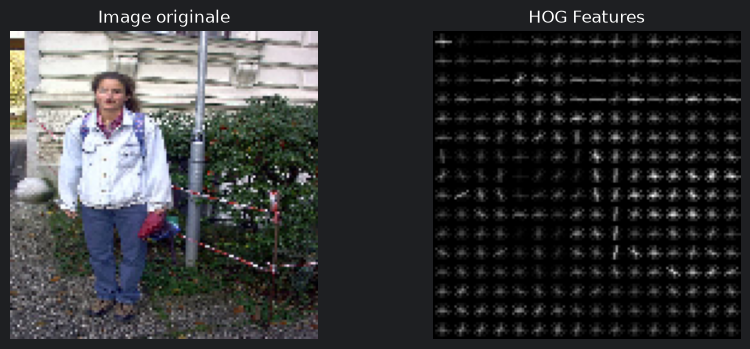

caltech_dataset/train_set\person\11.png


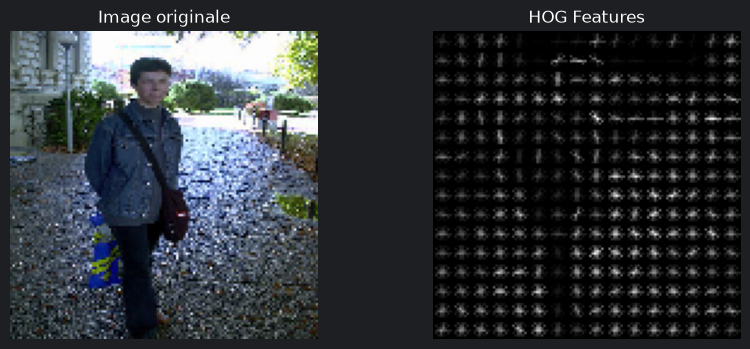

caltech_dataset/train_set\person\12.png


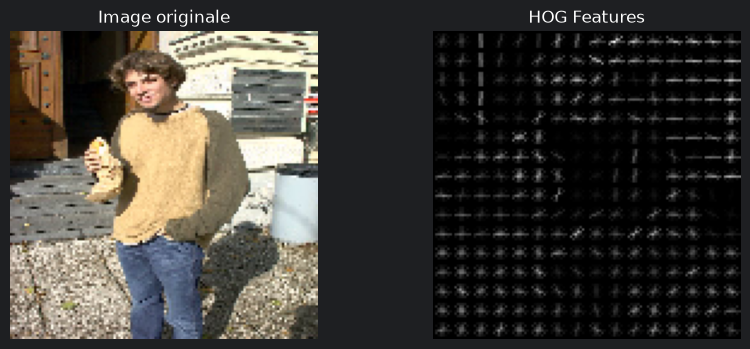

caltech_dataset/train_set\person\13.png


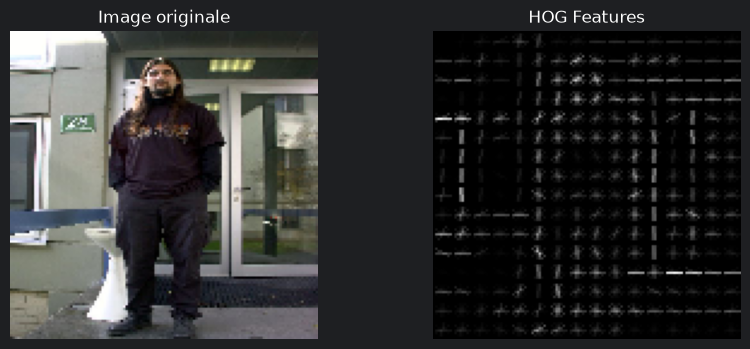

caltech_dataset/train_set\person\14.png


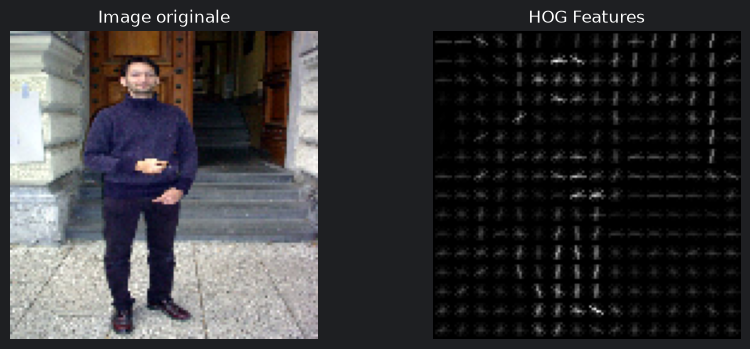

caltech_dataset/train_set\person\15.png


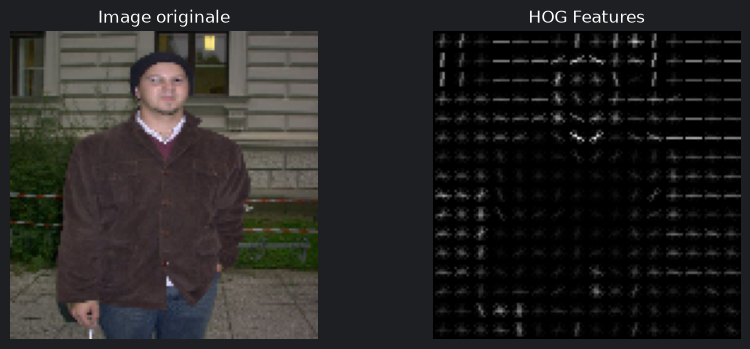

caltech_dataset/train_set\person\16.png


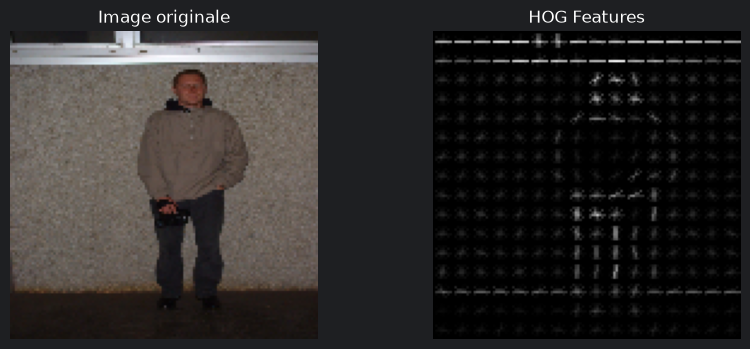

caltech_dataset/train_set\person\17.png


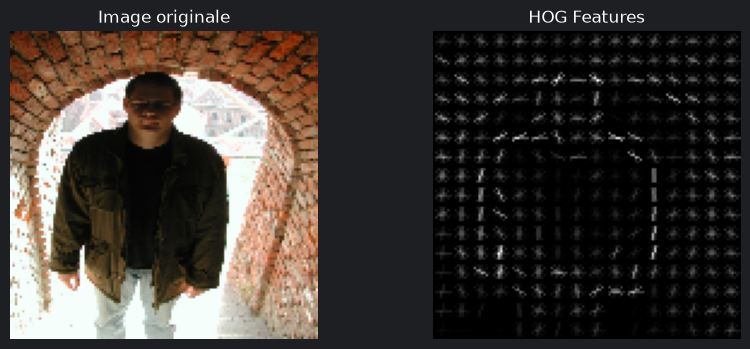

caltech_dataset/train_set\person\18.png


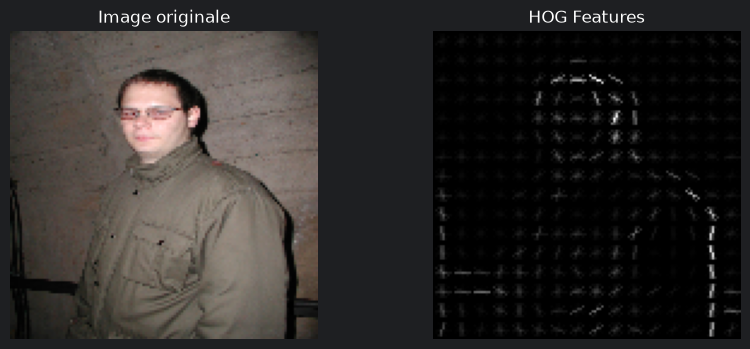

caltech_dataset/train_set\person\19.png


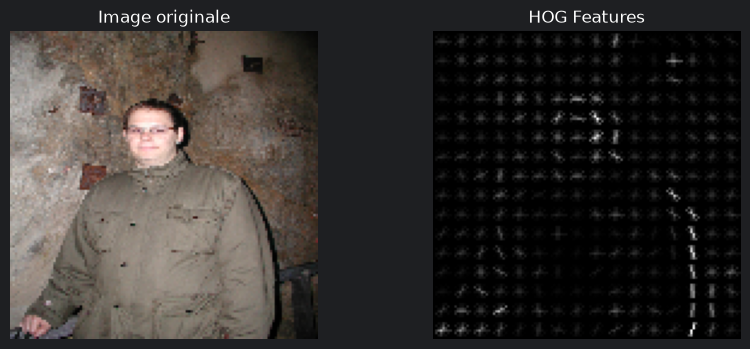

caltech_dataset/train_set\person\20.png


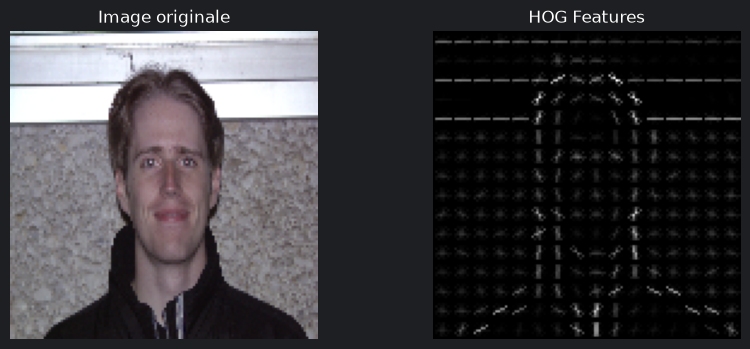

[INFO] Extraction terminée !
Nombre d'images : 60
Nombre d'étiquettes : 60


In [6]:
import os

# Début de l'extraction des caractéristiques pour les images d'apprentissage
print("[INFO] Extraction des caractéristiques : valeurs brutes, histogramme de couleurs, HOG, LBP")
#TODO: Ajoutez un vecteur pour stocker les étiquettes des classes associées aux images d'entraînement
train_data_hog = []  # Liste pour stocker les caractéristiques HOG
#TODO: Ajoutez le vecteur train_labels pour stocker les étiquettes des classes d'entraînement
train_labels = []
# Définition de la taille standard à laquelle redimensionner toutes les images
IMAGE_SIZE = (128, 128)

for imagePath in paths.list_images('caltech_dataset/train_set'):
    print(imagePath)
    # TODO : Extraire la classe de chaque image à partir de son chemin
    label = os.path.basename(os.path.dirname(imagePath))
    image = cv2.imread(imagePath)
    #TODO: redimensionner l'image
    image = cv2.resize(image, IMAGE_SIZE)
    #TODO: Convertir l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    (H, hogImage) = feature.hog(gray_image, orientations=9, pixels_per_cell=(8, 8),
                                cells_per_block=(2, 2), transform_sqrt=True,
                                block_norm="L1", visualize=True)

    hogImage = exposure.rescale_intensity(hogImage, out_range=(0, 255)).astype("uint8")
    # TODO : Afficher l'image originale pour visualisation
     # Afficher l'image originale
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")
    # TODO : Afficher l'image HOG pour visualisation
     # Afficher l'image HOG
    plt.subplot(1, 2, 2)
    plt.imshow(hogImage, cmap="gray")
    plt.title("HOG Features")
    plt.axis("off")
    plt.show()
    #TODO : Ajouter le vecteur de caractéristiques H à la liste des données d'apprentissage
    train_labels.append(label)
    train_data_hog.append(H)

print("[INFO] Extraction terminée !")
print("Nombre d'images :", len(train_data_hog))
print("Nombre d'étiquettes :", len(train_labels))

In [7]:
print("Taille de chaque vecteur HOG :", len(train_data_hog[0]))

Taille de chaque vecteur HOG : 8100


#	Préparation des données de Test  & Extraction des caractéristiques HOG

In [23]:
# Extraction des caractéristiques pour les données de test

#TODO: Ajoutez les vecteurs test_data_hog et test_labels  pour stockerles caractéristiques HOG  et les étiquettes des classes de test
test_data_hog = []
test_label = []

In [24]:
for imagePath in paths.list_images('caltech_dataset/test_set'):
    # TODO : Extraire la classe de chaque image à partir de son chemin
    label = os.path.basename(os.path.dirname(imagePath))
    image = cv2.imread(imagePath)
    #TODO: redimensionner l'image
    image = cv2.resize(image, IMAGE_SIZE)
    #TODO: Convertir l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    (H, hogImage) = feature.hog(gray_image, orientations=9, pixels_per_cell=(8, 8),
                                cells_per_block=(2, 2), transform_sqrt=True,
                                block_norm="L1", visualize=True)
   #TODO : Ajouter le vecteur de caractéristiques H à la liste des données de test
    test_data_hog.append(H)
    test_label.append(label)
print('preocess complete suscefully ', len(test_data_hog))

preocess complete suscefully  15


#Partie II : Classification

#Initialisation, Entraînement et évaluation des modèles de classification




In [13]:
# Initialisation des modèles de classification
model1 = KNeighborsClassifier(n_neighbors=1)
model2 = SVC(kernel='linear')

In [14]:
# Entraînement et évaluation du modèle KNN

model1.fit(train_data_hog, train_labels)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U9](3,)","['car','motorbike','person']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [21]:

# TODO : Entraîner le modèle SVM avec les données HOG et prédire les étiquettes pour les images de test
model2.fit(train_data_hog, train_labels)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [32]:
predict_svm = model2.predict(test_data_hog)

#Prediction et Evaluation de models

In [27]:
# Évaluer la précision du modèle KNN en comparant les classes prédites avec les vraies classes
predicted_classes1 = model1.predict(test_data_hog)
accuracy_knn = np.mean(predicted_classes1 == np.array(test_label))
print(f"Précision du modèle KNN : {accuracy_knn:.2f}")

Précision du modèle KNN : 0.80


[INFO] Évaluation du modèle KNN
Matrice de confusion pour KNN :
 [[4 1 0]
 [0 4 1]
 [0 1 4]]
Rapport de classification pour KNN :
               precision    recall  f1-score   support

         car       1.00      0.80      0.89         5
   motorbike       0.67      0.80      0.73         5
      person       0.80      0.80      0.80         5

    accuracy                           0.80        15
   macro avg       0.82      0.80      0.81        15
weighted avg       0.82      0.80      0.81        15



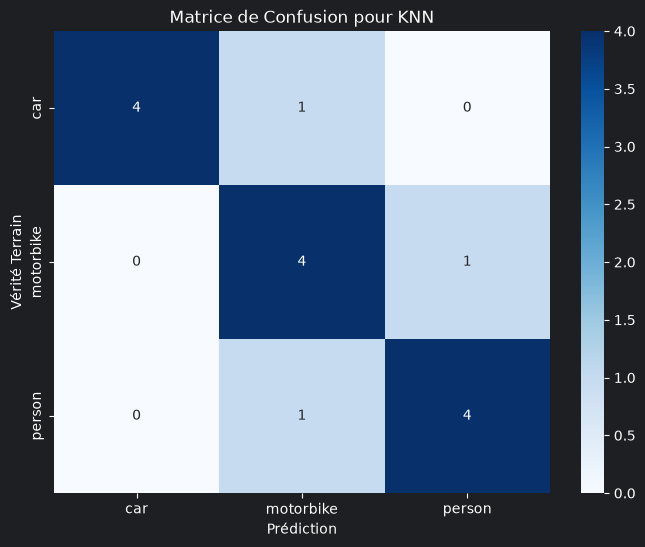

In [31]:
# Matrice de confusion et rapport de classification pour le modèle KNN
print("[INFO] Évaluation du modèle KNN")
conf_matrix_knn = confusion_matrix(test_label, predicted_classes1)
print("Matrice de confusion pour KNN :\n", conf_matrix_knn)
print("Rapport de classification pour KNN :\n", classification_report(test_label, predicted_classes1))

# Visualisation de la matrice de confusion pour KNN
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(test_label), yticklabels=np.unique(test_label))
plt.title("Matrice de Confusion pour KNN")
plt.xlabel("Prédiction")
plt.ylabel("Vérité Terrain")
plt.show()

In [34]:
# TODO : Évaluer la précision du modèle SVM en comparant les classes prédites avec les vraies classes
from sklearn.metrics import accuracy_score
accuracy_score(predict_svm, test_label)

1.0

[INFO] Évaluation du modèle SVM
Matrice de confusion pour SVM :
 [[4 1 0]
 [0 4 1]
 [0 1 4]]
Rapport de classification pour SVM :
               precision    recall  f1-score   support

         car       1.00      1.00      1.00         5
   motorbike       1.00      1.00      1.00         5
      person       1.00      1.00      1.00         5

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



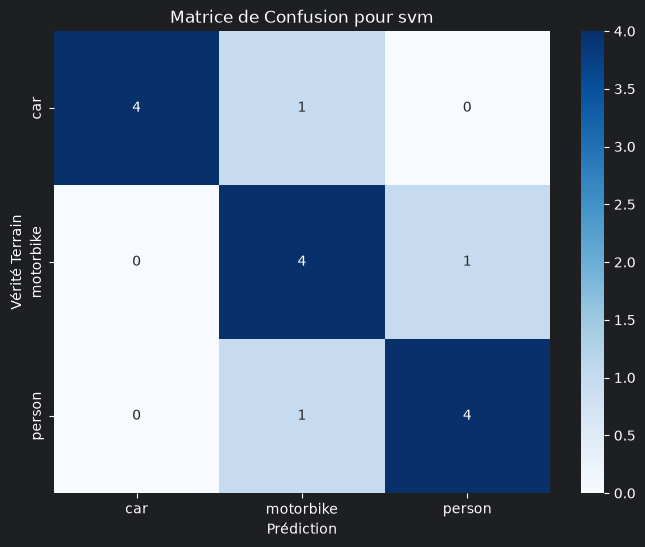

In [33]:
# TODO : Évaluer la précision du modèle SVM avec la Matrice de confusion et le rapport de classification
print("[INFO] Évaluation du modèle SVM")
conf_matrix_SVM = confusion_matrix(test_label, predict_svm)
print("Matrice de confusion pour SVM :\n", conf_matrix_knn)
print("Rapport de classification pour SVM :\n", classification_report(test_label, predict_svm))

# Visualisation de la matrice de confusion pour KNN
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(test_label), yticklabels=np.unique(test_label))
plt.title("Matrice de Confusion pour svm")
plt.xlabel("Prédiction")
plt.ylabel("Vérité Terrain")
plt.show()